# 02 — Análisis exploratorio

## Objetivo

Entender la variable objetivo y encontrar qué información podría predecirla, **antes** de
construir variables. Cada análisis de este cuadernillo responde una pregunta concreta y
termina en una decisión para los pasos siguientes:

1. ¿Está balanceada la variable objetivo?
2. ¿Por qué Team A gana más que Team B?
3. ¿Qué mapas se juegan y cómo cambian con los años?
4. ¿Hay ventaja de ataque o defensa según el mapa?
5. ¿Qué tan parejos son los mapas?
6. ¿Cuánta historia tiene cada equipo?
7. ¿El rendimiento pasado de un equipo dice algo sobre su siguiente mapa?

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import INTERIM_DIR
from src.data_loading import MAP_KEY, load_table
from src.plotting import set_style, save_fig

set_style()
maps = pd.read_csv(INTERIM_DIR / "maps.csv")
maps.shape

(27368, 14)

## 1. ¿Está balanceada la variable objetivo?

`team_a_win` vale 1 cuando gana el equipo listado como Team A. Si A y B fueran un orden
arbitrario, se esperaría un 50 %.

In [2]:
balance = maps.groupby("year")["team_a_win"].agg(team_a_winrate="mean", maps="size")
print(f"Global: Team A gana el {maps['team_a_win'].mean():.1%} de los mapas")
balance.round(3)

Global: Team A gana el 57.3% de los mapas


,team_a_winrate,maps
year,,
2021,0.583,14428
2022,0.587,8848
2023,0.511,830
2024,0.519,1104
2025,0.511,1272
2026,0.472,886


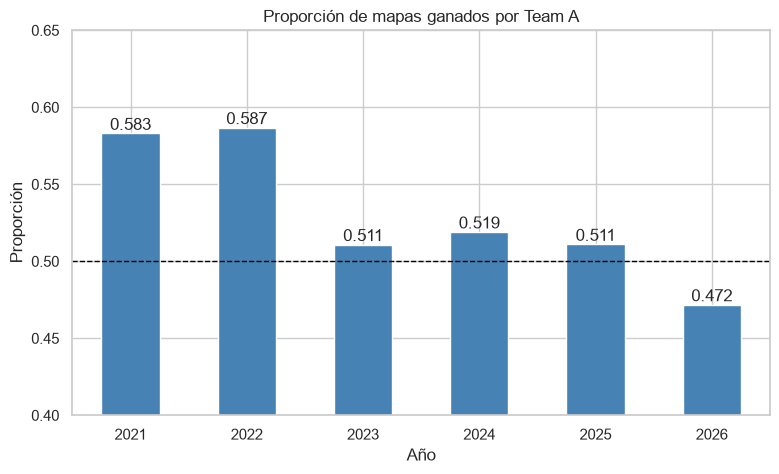

In [3]:
ax = balance["team_a_winrate"].plot.bar(color="steelblue")
ax.axhline(0.5, color="black", linestyle="--", linewidth=1)
ax.set(title="Proporción de mapas ganados por Team A", xlabel="Año", ylabel="Proporción", ylim=(0.4, 0.65))
ax.bar_label(ax.containers[0], fmt="%.3f")
plt.xticks(rotation=0)
save_fig("02_balance_objetivo_por_anio")
plt.show()

Globalmente Team A gana el 57 % de los mapas, pero el desbalance está concentrado en
2021–2022 (58 %). De 2023 en adelante el objetivo está prácticamente balanceado.

## 2. ¿Por qué Team A gana más que Team B?

Ser "Team A" no debería dar ninguna ventaja: es solo el equipo que la web muestra a la
izquierda. Primero se confirma que es así.

In [4]:
first_in_name = maps.apply(lambda row: row["match_name"].startswith(row["team_a"]), axis=1)
print(f"Team A es el primer equipo del nombre del partido en el {first_in_name.mean():.1%} de los mapas")

Team A es el primer equipo del nombre del partido en el 99.8% de los mapas


La hipótesis es que en los cuadros de eliminación el equipo mejor clasificado (el favorito)
se lista primero. Si es cierto, el sesgo debería ser mayor en los clasificatorios abiertos,
donde un equipo profesional suele enfrentarse a uno amateur.

In [5]:
early = maps[maps["year"] <= 2022]
is_open = early["stage"].str.contains("Open Qual")
(early.groupby(is_open.map({True: "Clasificatorio abierto", False: "Otras etapas"}))["team_a_win"]
 .agg(team_a_winrate="mean", maps="size").round(3))

,team_a_winrate,maps
stage,,
Clasificatorio abierto,0.614,10882
Otras etapas,0.558,12394


Se confirma: en clasificatorios abiertos Team A gana el 61 %, frente al 56 % del resto.
La posición no es aleatoria; **contiene información sobre quién es el favorito**.

Esto es un problema para el modelo. Si se entrena tal cual, aprendería "Team A suele ganar",
una regla que depende de cómo la web ordena los equipos y que dejó de cumplirse desde 2023.

**Decisión:** en el cuadernillo 03 se intercambiarán Team A y Team B al azar en la mitad de
los mapas. Así el objetivo queda balanceado al 50 % y el modelo solo puede apoyarse en las
variables de rendimiento, no en la posición.

## 3. ¿Qué mapas se juegan y cómo cambian con los años?

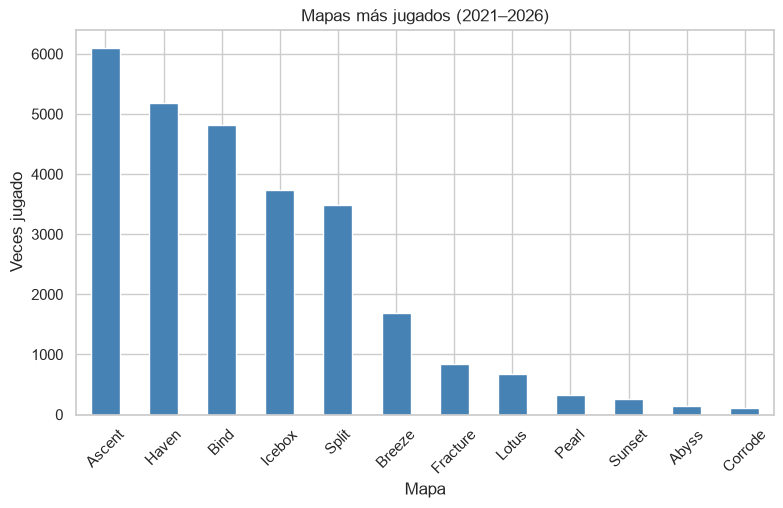

In [6]:
map_counts = maps["map"].value_counts()
ax = map_counts.plot.bar(color="steelblue")
ax.set(title="Mapas más jugados (2021–2026)", xlabel="Mapa", ylabel="Veces jugado")
plt.xticks(rotation=45)
save_fig("02_mapas_mas_jugados")
plt.show()

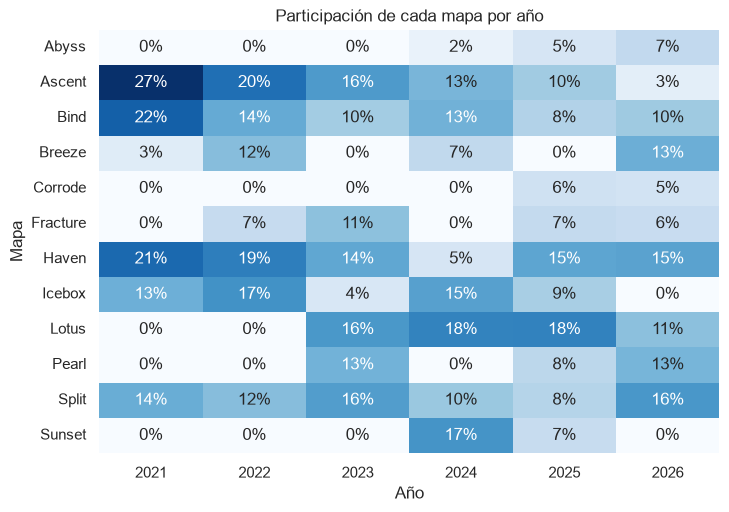

In [7]:
map_share = pd.crosstab(maps["map"], maps["year"], normalize="columns")
plt.figure(figsize=(8, 5.5))
sns.heatmap(map_share, annot=True, fmt=".0%", cmap="Blues", cbar=False)
plt.title("Participación de cada mapa por año")
plt.xlabel("Año"); plt.ylabel("Mapa")
save_fig("02_mapas_por_anio")
plt.show()

La rotación de mapas cambia cada temporada: Ascent pasa de ser uno de cada cuatro mapas en
2021 a casi desaparecer en 2026; Lotus, Sunset, Abyss y Corrode no existían en los primeros
años; Icebox y Sunset no se juegan en 2026.

**Implicación:** el nombre del mapa por sí solo no es una buena variable, porque el modelo se
entrena con unos mapas y se prueba con otros. Lo que sí puede generalizar es **cómo le va a
cada equipo en ese mapa** (experiencia y winrate del equipo en el mapa).

## 4. ¿Hay ventaja de ataque o defensa según el mapa?

`maps_scores` trae las rondas que cada equipo ganó atacando y defendiendo. Sumando ambos
equipos se obtiene qué lado gana más rondas en cada mapa.

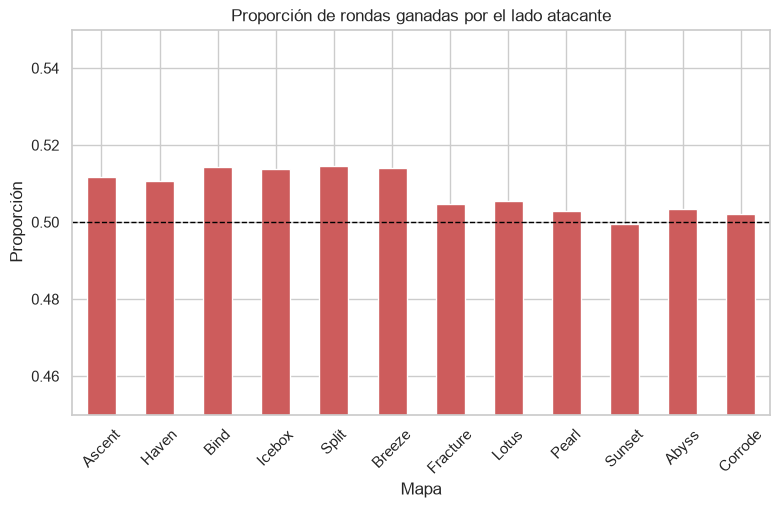

map,Ascent,Haven,Bind,Icebox,Split,Breeze,Fracture,Lotus,Pearl,Sunset,Abyss,Corrode
attack_share,0.512,0.511,0.514,0.514,0.515,0.514,0.505,0.506,0.503,0.5,0.503,0.502


In [8]:
raw = load_table("matches/maps_scores.csv").drop_duplicates(MAP_KEY + ["Year"], keep=False)
raw = raw.rename(columns={"Tournament": "tournament", "Stage": "stage", "Match Type": "match_type",
                          "Match Name": "match_name", "Map": "map", "Year": "year"})
side_cols = ["Team A Attacker Score", "Team A Defender Score", "Team B Attacker Score",
             "Team B Defender Score", "Team A Overtime Score"]
join_key = ["tournament", "stage", "match_type", "match_name", "map", "year"]
detail = maps.merge(raw[join_key + side_cols], on=join_key, how="left")
assert len(detail) == len(maps)

detail["attack_rounds"] = detail["Team A Attacker Score"] + detail["Team B Attacker Score"]
detail["defense_rounds"] = detail["Team A Defender Score"] + detail["Team B Defender Score"]
sides = detail.groupby("map")[["attack_rounds", "defense_rounds"]].sum()
sides["attack_share"] = sides["attack_rounds"] / sides.sum(axis=1)
sides = sides.loc[map_counts.index]

ax = sides["attack_share"].plot.bar(color="indianred")
ax.axhline(0.5, color="black", linestyle="--", linewidth=1)
ax.set(title="Proporción de rondas ganadas por el lado atacante", xlabel="Mapa", ylabel="Proporción",
       ylim=(0.45, 0.55))
plt.xticks(rotation=45)
save_fig("02_ataque_vs_defensa_por_mapa")
plt.show()
sides["attack_share"].round(3).to_frame().T

La diferencia entre lados es mínima: el ataque gana entre el 50 % y el 51.5 % de las rondas
en todos los mapas. Además, ambos equipos juegan los dos lados en cada mapa, así que esa
pequeña ventaja se reparte.

**Decisión:** el lado inicial no se incluye como variable. No aporta señal y tampoco está
disponible en los datos de forma clara antes del mapa.

## 5. ¿Qué tan parejos son los mapas?

Se analiza la diferencia de rondas entre ganador y perdedor, y con qué frecuencia hay *overtime*.

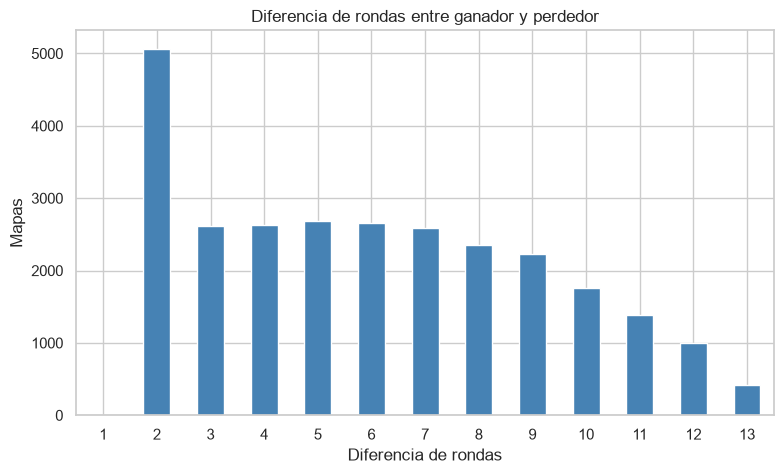

Diferencia mediana: 6 rondas
Mapas con overtime: 9.1%
Mapas decididos por 3 rondas o menos: 28.1%


In [9]:
detail["margin"] = (detail["team_a_score"] - detail["team_b_score"]).abs()
detail["overtime"] = detail["Team A Overtime Score"].notna()

ax = detail["margin"].value_counts().sort_index().plot.bar(color="steelblue")
ax.set(title="Diferencia de rondas entre ganador y perdedor", xlabel="Diferencia de rondas", ylabel="Mapas")
plt.xticks(rotation=0)
save_fig("02_diferencia_de_rondas")
plt.show()

print(f"Diferencia mediana: {detail['margin'].median():.0f} rondas")
print(f"Mapas con overtime: {detail['overtime'].mean():.1%}")
print(f"Mapas decididos por 3 rondas o menos: {(detail['margin'] <= 3).mean():.1%}")

La distribución es bastante plana entre 3 y 9 rondas de diferencia, con un pico en 2 (que
incluye todos los *overtime*, el 9 % de los mapas). Casi tres de cada diez mapas se deciden
por 3 rondas o menos: hay una parte importante de resultados cerrados, donde un par de rondas
cambian el ganador. Eso anticipa un **techo de precisión**: ningún modelo previo al partido
va a acertar esos mapas de forma consistente.

**Decisión:** la diferencia de rondas histórica se usará como variable; dice más que el
simple ganó/perdió (no es lo mismo ganar 13–2 que 13–11).

## 6. ¿Cuánta historia tiene cada equipo?

In [10]:
team_maps = pd.concat([maps["team_a"], maps["team_b"]]).value_counts()
print(team_maps.describe().round(1).to_string())
print(f"\nEquipos con 5 mapas o menos: {(team_maps <= 5).mean():.1%}")
team_maps.head(8).to_frame("maps").T

count    3970.0
mean       13.8
std        34.4
min         1.0
25%         2.0
50%         4.0
75%        11.0
max       550.0

Equipos con 5 mapas o menos: 56.2%


,Paper Rex,FNATIC,G2 Esports,Sentinels,Team Liquid,Gen.G,100 Thieves,T1
maps,550,466,449,442,432,406,387,355


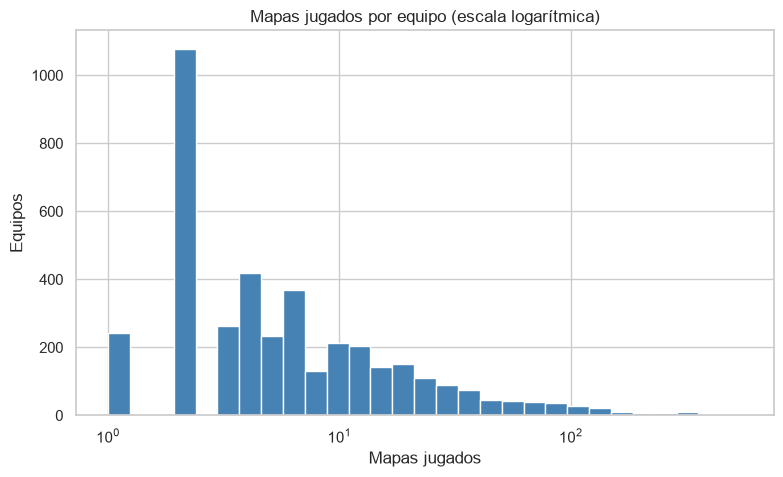

In [11]:
fig, ax = plt.subplots()
ax.hist(team_maps, bins=np.logspace(0, np.log10(team_maps.max()), 30), color="steelblue")
ax.set_xscale("log")
ax.set(title="Mapas jugados por equipo (escala logarítmica)", xlabel="Mapas jugados", ylabel="Equipos")
save_fig("02_mapas_por_equipo")
plt.show()

La distribución tiene una cola muy larga: la mitad de los equipos jugó 4 mapas o menos (son
los equipos amateur de los clasificatorios de 2021–2022), mientras que los equipos de las
ligas actuales acumulan cientos de mapas.

**Decisión:** el modelo necesita saber **cuánta evidencia hay** detrás de cada estadística.
Un winrate de 100 % con 2 mapas no vale lo mismo que uno de 65 % con 200. Se incluirá el
número de mapas previos como variable.

## 7. ¿El rendimiento pasado dice algo sobre el siguiente mapa?

Es la pregunta de fondo del proyecto. Se calcula, para cada equipo, su winrate acumulado en
**etapas anteriores** (respetando la regla del cuadernillo 01) y se compara la diferencia de
winrate entre Team A y Team B con quién ganó. Para que el winrate sea estable, se toman solo
los mapas donde ambos equipos tienen al menos 5 mapas previos.

In [12]:
long = pd.concat([
    maps[["game_id", "stage_block", "team_a", "team_a_win"]]
        .set_axis(["game_id", "stage_block", "team", "won"], axis=1).assign(side="a"),
    maps[["game_id", "stage_block", "team_b", "team_a_win"]]
        .set_axis(["game_id", "stage_block", "team", "won"], axis=1)
        .assign(side="b", won=lambda d: 1 - d["won"]),
])
# victorias y mapas por equipo y etapa; el acumulado excluye la etapa actual
per_stage = (long.groupby(["team", "stage_block"])["won"].agg(["sum", "count"])
             .reset_index().sort_values(["team", "stage_block"]))
previous = per_stage.groupby("team")[["sum", "count"]].cumsum() - per_stage[["sum", "count"]]
per_stage["prior_maps"] = previous["count"]
per_stage["prior_winrate"] = previous["sum"] / previous["count"].where(previous["count"] > 0)

long = long.merge(per_stage[["team", "stage_block", "prior_maps", "prior_winrate"]],
                  on=["team", "stage_block"])
wide = long.pivot(index="game_id", columns="side", values=["prior_winrate", "prior_maps"])
wide.columns = ["winrate_a", "winrate_b", "maps_a", "maps_b"]
signal = maps.merge(wide, on="game_id")
signal["winrate_diff"] = signal["winrate_a"] - signal["winrate_b"]
signal = signal[(signal["maps_a"] >= 5) & (signal["maps_b"] >= 5)]
print("Mapas con historial suficiente en ambos equipos:", len(signal))

Mapas con historial suficiente en ambos equipos: 13956


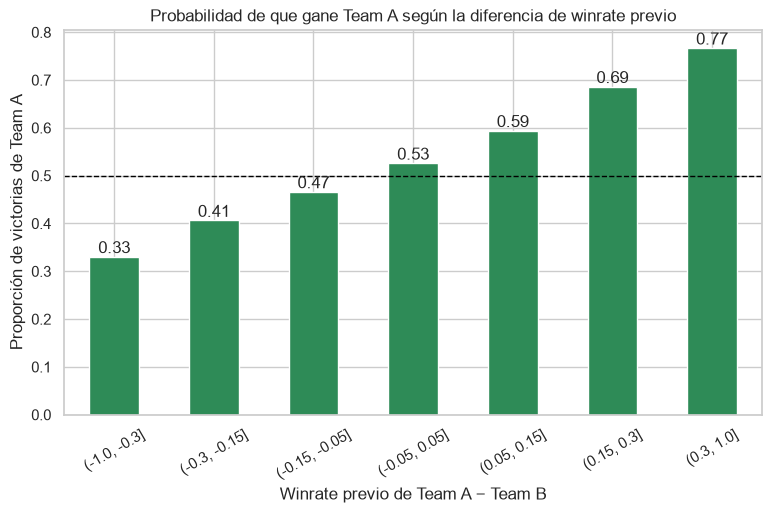

,mean,size
winrate_diff,,
"(-1.0, -0.3]",0.331,369
"(-0.3, -0.15]",0.406,1203
"(-0.15, -0.05]",0.466,2513
"(-0.05, 0.05]",0.526,4333
"(0.05, 0.15]",0.594,3133
"(0.15, 0.3]",0.686,1757
"(0.3, 1.0]",0.767,648


In [13]:
bins = [-1, -0.3, -0.15, -0.05, 0.05, 0.15, 0.3, 1]
by_bin = signal.groupby(pd.cut(signal["winrate_diff"], bins), observed=True)["team_a_win"].agg(["mean", "size"])

ax = by_bin["mean"].plot.bar(color="seagreen")
ax.axhline(0.5, color="black", linestyle="--", linewidth=1)
ax.set(title="Probabilidad de que gane Team A según la diferencia de winrate previo",
       xlabel="Winrate previo de Team A − Team B", ylabel="Proporción de victorias de Team A")
ax.bar_label(ax.containers[0], fmt="%.2f")
plt.xticks(rotation=30)
save_fig("02_senal_winrate_previo")
plt.show()
by_bin.round(3)

La relación es clara y monótona: cuando Team A llega con un winrate previo 30 puntos peor,
gana un tercio de las veces; cuando llega 30 puntos mejor, gana más de tres de cada cuatro.

¿Qué tan seguido acierta la regla simple "gana el equipo con mejor winrate previo"?

In [14]:
decided = signal[signal["winrate_diff"] != 0]
better_team_won = (decided["winrate_diff"] > 0) == (decided["team_a_win"] == 1)
rule = (better_team_won.groupby(decided["year"]).agg(accuracy="mean", maps="size"))
print(f"Acierto global de la regla: {better_team_won.mean():.1%}")
rule.round(3)

Acierto global de la regla: 58.3%


,accuracy,maps
year,,
2021,0.613,5764
2022,0.561,4192
2023,0.553,716
2024,0.555,1060
2025,0.576,1208
2026,0.560,837


La regla acierta cerca del 58 % de las veces: mejor que lanzar una moneda, pero lejos de ser
infalible, y con menos acierto en los años recientes (55–58 %), donde los equipos son más
parejos. Este número es la **línea base** que el modelo tendrá que superar.

## Conclusiones

| # | Hallazgo | Decisión para el modelado |
|---|---|---|
| 1 | Team A gana el 57 % de los mapas (58 % en 2021–2022, ~51 % desde 2023). | No se puede usar la exactitud "a secas" sin comparar contra una línea base. |
| 2 | El sesgo viene de que la web lista primero al favorito (61 % en clasificatorios abiertos). | Intercambiar A y B al azar en la mitad de los mapas para que el modelo no aprenda la posición. |
| 3 | La rotación de mapas cambia cada año; hay mapas que solo existen en los años de prueba. | No usar el nombre del mapa como variable; usar el rendimiento del equipo **en ese mapa**. |
| 4 | El ataque gana entre 50 % y 51.5 % de las rondas en todos los mapas. | No incluir el lado como variable. |
| 5 | 28 % de los mapas se decide por 3 rondas o menos; 9 % va a *overtime*. | Hay un techo de precisión; usar la diferencia de rondas histórica como variable. |
| 6 | La mitad de los equipos jugó 4 mapas o menos; los de las ligas actuales, cientos. | Incluir el número de mapas previos como medida de evidencia. |
| 7 | La diferencia de winrate previo predice el resultado de forma monótona (33 % → 77 %). | El historial sí contiene señal: es la base de las variables del cuadernillo 03. |
| 8 | La regla "gana el de mejor winrate previo" acierta ~58 %. | Línea base a superar en los cuadernillos 05 y 06. |

**Siguiente paso (cuadernillo 03):** construir las variables históricas de cada equipo, usando
solo etapas anteriores, y armar el dataset de modelado.